# Algoritmo K-Nearest Neighbors (KNN) desde Cero

En este notebook se implementa el algoritmo de clasificación **K-Nearest Neighbors (KNN)** desde cero utilizando únicamente `NumPy` para las operaciones matemáticas, sin emplear librerías externas para la lógica del modelo.

El flujo del notebook incluye:
1. **Generación del dataset** sintético mediante `make_blobs` de `scikit-learn`.
2. **Visualización gráfica** de la distribución del dataset y sus clases.
3. **División de datos** en entrenamiento y prueba implementada desde cero.
4. **Implementación de la clase `KNN`** (distancia euclidiana, búsqueda de los $k$ vecinos más cercanos y votación por mayoría).
5. **Evaluación y gráficas** de las regiones de decisión y comparación para distintos valores de $k$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import Counter
from sklearn.datasets import make_blobs

## 1. Generación y Visualización del Dataset con `make_blobs`

In [2]:
# Generamos un dataset con 300 muestras, 3 centros (clases) y 2 características
X, y, centers = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    cluster_std=1.3,
    random_state=42,
    return_centers=True
)

print(f"Dimensiones de X (características): {X.shape}")
print(f"Dimensiones de y (etiquetas): {y.shape}")
print(f"Clases únicas: {np.unique(y)}")

Dimensiones de X (características): (300, 2)
Dimensiones de y (etiquetas): (300,)
Clases únicas: [0 1 2]


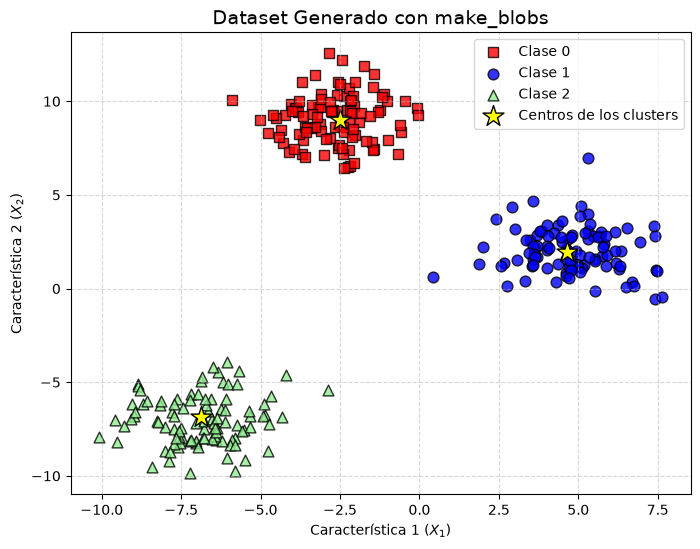

In [3]:
# Gráfica del dataset generado
colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
markers = ('s', 'o', '^', 'v', 'x')

plt.figure(figsize=(8, 6))
for idx, cl in enumerate(np.unique(y)):
    plt.scatter(
        X[y == cl, 0],
        X[y == cl, 1],
        c=colors[idx],
        marker=markers[idx],
        label=f'Clase {cl}',
        alpha=0.8,
        edgecolors='black',
        s=60
    )

# Graficamos los centros reales de cada cluster
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='yellow',
    marker='*',
    s=250,
    edgecolors='black',
    label='Centros de los clusters'
)

plt.title('Dataset Generado con make_blobs', fontsize=14)
plt.xlabel('Característica 1 ($X_1$)')
plt.ylabel('Característica 2 ($X_2$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. División del Dataset (Entrenamiento y Prueba) desde Cero

Muestras de entrenamiento: 225
Muestras de prueba: 75


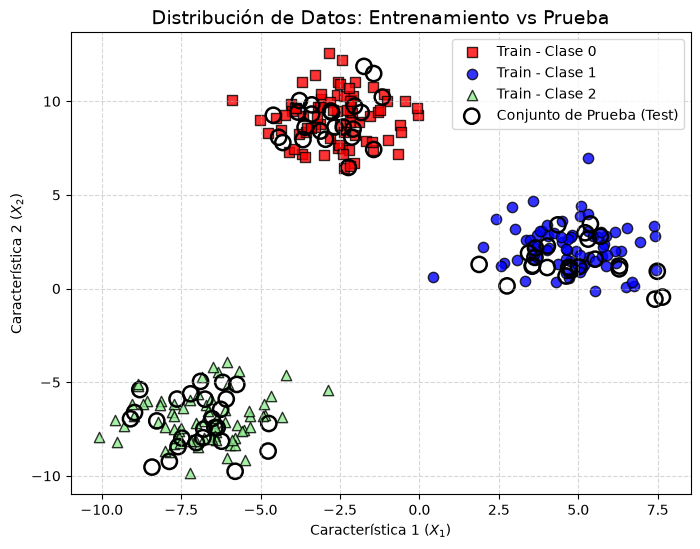

In [4]:
def dividir_train_test(X, y, test_size=0.25, random_state=42):
    """Divide el dataset en conjuntos de entrenamiento y prueba sin usar librerías externas."""
    rng = np.random.default_rng(random_state)
    indices = rng.permutation(len(X))
    test_count = int(len(X) * test_size)
    
    test_idx = indices[:test_count]
    train_idx = indices[test_count:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = dividir_train_test(X, y, test_size=0.25, random_state=42)

print(f"Muestras de entrenamiento: {len(X_train)}")
print(f"Muestras de prueba: {len(X_test)}")

# Visualización de la partición Entrenamiento vs Prueba
plt.figure(figsize=(8, 6))
for idx, cl in enumerate(np.unique(y)):
    plt.scatter(
        X_train[y_train == cl, 0],
        X_train[y_train == cl, 1],
        c=colors[idx],
        marker=markers[idx],
        label=f'Train - Clase {cl}',
        alpha=0.8,
        edgecolors='black',
        s=55
    )

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    facecolors='none',
    edgecolors='black',
    linewidths=1.8,
    marker='o',
    s=120,
    label='Conjunto de Prueba (Test)'
)

plt.title('Distribución de Datos: Entrenamiento vs Prueba', fontsize=14)
plt.xlabel('Característica 1 ($X_1$)')
plt.ylabel('Característica 2 ($X_2$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 3. Implementación del Algoritmo KNN desde Cero

El algoritmo **KNN** clasifica un nuevo punto $x$ siguiendo tres pasos:
1. Calcular la **distancia euclidiana** entre $x$ y todos los puntos del conjunto de entrenamiento:
   $$d(x, x_i) = \sqrt{\sum_{j=1}^{d} (x_j - x_{i,j})^2}$$
2. Seleccionar los **$k$ vecinos más cercanos** (aquellos con menor distancia).
3. Asignar la clase más frecuente (**votación por mayoría**) entre esos $k$ vecinos.

In [5]:
class KNN:
    def __init__(self, k=5):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """Almacena los datos de entrenamiento."""
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        return self

    @staticmethod
    def distancia_euclidiana(x1, x2):
        """Calcula la distancia euclidiana entre un punto x1 y un arreglo de puntos x2."""
        return np.sqrt(np.sum((x1 - x2) ** 2, axis=1))

    def _predecir_punto(self, x):
        """Predice la clase de una sola muestra x."""
        # 1. Calcular distancias hacia todos los puntos de entrenamiento
        distancias = self.distancia_euclidiana(x, self.X_train)
        
        # 2. Obtener los índices de los k vecinos más cercanos
        k_indices = np.argsort(distancias)[:self.k]
        
        # 3. Obtener las etiquetas de los k vecinos y votar por mayoría
        k_etiquetas = self.y_train[k_indices]
        mas_comun = Counter(k_etiquetas).most_common(1)[0][0]
        return mas_comun

    def predict(self, X):
        """Predice las clases para un conjunto de muestras X."""
        X = np.array(X)
        predicciones = [self._predecir_punto(x) for x in X]
        return np.array(predicciones)

    def score(self, X, y):
        """Calcula la exactitud (accuracy) del modelo."""
        y_pred = self.predict(X)
        return np.mean(y_pred == y)

## 4. Entrenamiento, Predicción y Evaluación

In [6]:
# Instanciamos y entrenamos nuestro clasificador KNN con k=5
knn = KNN(k=5)
knn.fit(X_train, y_train)

# Realizamos predicciones sobre el conjunto de prueba
y_pred = knn.predict(X_test)
exactitud = knn.score(X_test, y_test)

print(f"Exactitud (Accuracy) en prueba con k={knn.k}: {exactitud * 100:.2f}%")
print("Primeras 15 predicciones:", y_pred[:15])
print("Primeras 15 etiquetas reales:", y_test[:15])

Exactitud (Accuracy) en prueba con k=5: 100.00%
Primeras 15 predicciones: [0 0 1 1 1 2 0 2 0 1 2 0 2 2 1]
Primeras 15 etiquetas reales: [0 0 1 1 1 2 0 2 0 1 2 0 2 2 1]


## 5. Visualización de las Regiones de Decisión del KNN

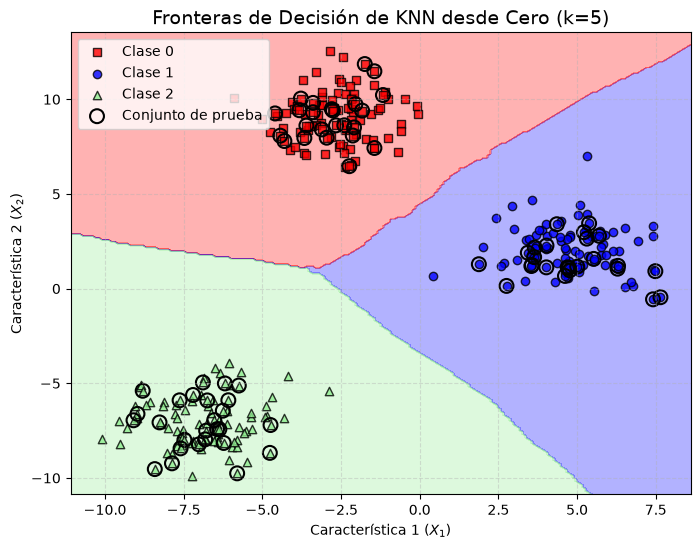

In [7]:
def plot_decision_regions(x, y, classifier, test_idx=None, resolution=0.1, ax=None):
    markers = ('s', 'o', '^', 'v', 'x')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    if ax is None:
        ax = plt.gca()

    x1_min, x1_max = x[:, 0].min() - 1, x[:, 0].max() + 1
    x2_min, x2_max = x[:, 1].min() - 1, x[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(
        np.arange(x1_min, x1_max, resolution),
        np.arange(x2_min, x2_max, resolution)
    )
    z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    z = z.reshape(xx1.shape)

    ax.contourf(xx1, xx2, z, alpha=0.3, cmap=cmap)
    ax.set_xlim(xx1.min(), xx1.max())
    ax.set_ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        ax.scatter(
            x=x[y == cl, 0],
            y=x[y == cl, 1],
            alpha=0.8,
            c=colors[idx],
            marker=markers[idx],
            label=f'Clase {cl}',
            edgecolors='black' if markers[idx] != 'x' else None
        )

    if test_idx is not None:
        x_test, y_test = x[test_idx, :], y[test_idx]
        ax.scatter(
            x_test[:, 0], x_test[:, 1],
            facecolors='none',
            edgecolors='black',
            alpha=1.0,
            linewidths=1.5,
            marker='o',
            s=100,
            label='Conjunto de prueba'
        )

# Combinamos train y test para graficar las regiones de decisión junto con el conjunto de prueba
X_combined = np.vstack((X_train, X_test))
y_combined = np.hstack((y_train, y_test))
test_indices = range(len(X_train), len(X_combined))

plt.figure(figsize=(8, 6))
plot_decision_regions(X_combined, y_combined, classifier=knn, test_idx=test_indices, resolution=0.1)
plt.title(f'Fronteras de Decisión de KNN desde Cero (k={knn.k})', fontsize=14)
plt.xlabel('Característica 1 ($X_1$)')
plt.ylabel('Característica 2 ($X_2$)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

## 6. Comparación Gráfica para Diferentes Valores de $k$

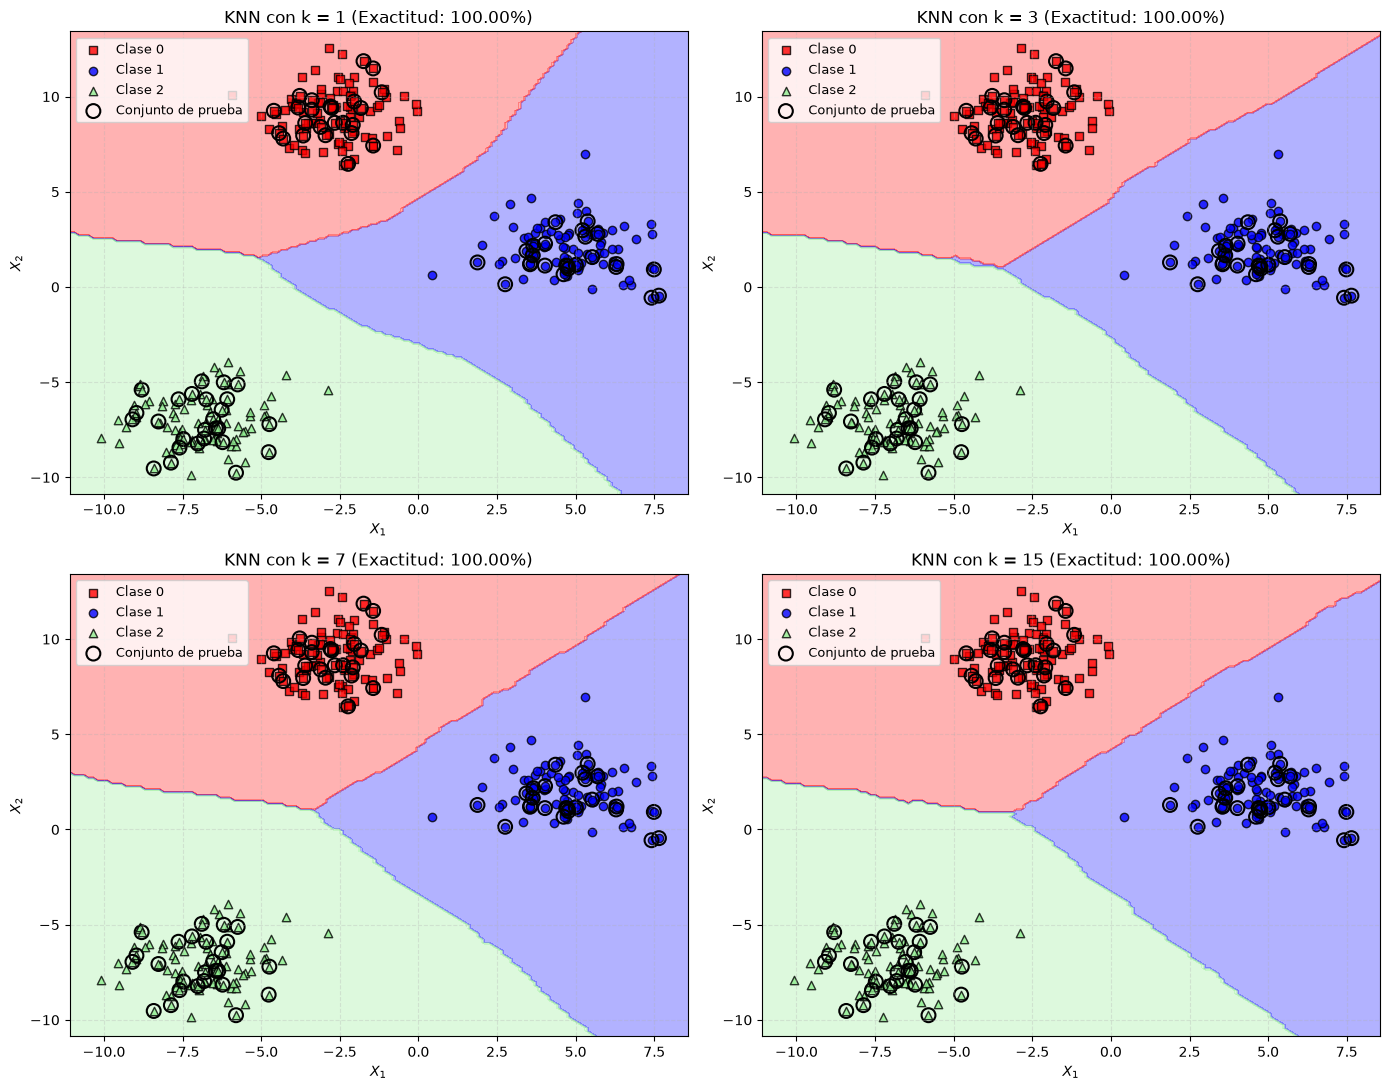

In [8]:
valores_k = [1, 3, 7, 15]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, k_val in zip(axes.ravel(), valores_k):
    modelo_k = KNN(k=k_val)
    modelo_k.fit(X_train, y_train)
    acc_k = modelo_k.score(X_test, y_test)
    
    plot_decision_regions(X_combined, y_combined, classifier=modelo_k, test_idx=test_indices, resolution=0.15, ax=ax)
    ax.set_title(f'KNN con k = {k_val} (Exactitud: {acc_k * 100:.2f}%)', fontsize=12)
    ax.set_xlabel('$X_1$')
    ax.set_ylabel('$X_2$')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()